# PINNs for Mechanical Engineers — Tutorial 7: Unsteady Vortex Shedding
### When a laminar wake becomes a clock: time-dependent flow past a circular cylinder

**Goal:** solve the two-dimensional, unsteady incompressible Navier–Stokes equations around a fixed circular cylinder using a physics-informed neural network (PINN), while staying entirely within the laminar regime.

This notebook deliberately keeps the same rhythm and coding style as Tutorial 6. The main change is one extra network input — time — and the diagnostics now include vorticity, lift, drag, and a shedding-frequency estimate.

## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **unsteady incompressible 2D Navier–Stokes equations** with a PINN.
- Extended the network from $(x,y)\mapsto(u,v,p)$ to $(x,y,t)\mapsto(u,v,p)$.
- Sampled an exterior domain containing a **curved no-slip cylinder boundary**.
- Added an **initial-condition loss** beside the PDE and boundary losses.
- Used a short inlet perturbation to break perfect top–bottom symmetry without adding a turbulence model.
- Used **Reynolds-number and time-horizon continuation** to make training less abrupt.
- Visualized velocity, pressure, streamlines, and vorticity at several times.
- Integrated pressure and viscous traction to estimate drag and lift.
- Estimated a laminar shedding frequency and Strouhal number from the lift signal.

## 2 — The problem and its reference

We solve the non-dimensional unsteady incompressible Navier–Stokes equations

$$
\begin{aligned}
u_t+u u_x+v u_y &= -p_x+\frac{1}{Re_D}(u_{xx}+u_{yy}),\\
v_t+u v_x+v v_y &= -p_y+\frac{1}{Re_D}(v_{xx}+v_{yy}),\\
u_x+v_y &= 0.
\end{aligned}
$$

The reference length is the cylinder diameter $D$, the reference velocity is the final free-stream speed $U_\infty$, and time is scaled by $D/U_\infty$. The cylinder has radius $R=D/2=0.5$ and the target is $Re_D=100$.

At this Reynolds number the two-dimensional wake is laminar but unsteady. No turbulence closure, eddy viscosity, $k$–$\varepsilon$, or LES model is used.

A perfectly symmetric PINN can settle on a symmetric wake. We therefore apply a very small, short-lived vertical inlet pulse. The pulse is part of the stated boundary condition, decays rapidly, and only seeds the natural wake instability.

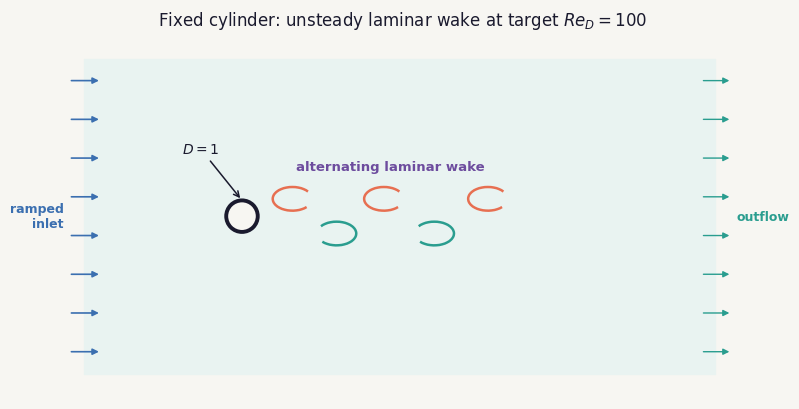

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle, Arc

BG="#f7f6f2"; CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"; BLUE="#3B6FB0"
XMIN=-5.0; XMAX=15.0; YMIN=-5.0; YMAX=5.0; R=0.5

fig,ax=plt.subplots(figsize=(11,4.2)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

# fluid box and cylinder
ax.fill_between([XMIN,XMAX],YMIN,YMAX,color="#e9f3f1",zorder=0)
ax.add_patch(Circle((0,0),R,facecolor=BG,edgecolor=INK,lw=2.8,zorder=6))

# inlet arrows
for yv in np.linspace(YMIN+0.7,YMAX-0.7,8):
    ax.add_patch(FancyArrowPatch((XMIN-0.5,yv),(XMIN+0.55,yv),arrowstyle='-|>',
                                 mutation_scale=9,color=BLUE,lw=1.2))
ax.text(XMIN-0.65,0,"ramped\ninlet",color=BLUE,ha='right',va='center',fontsize=9,weight='bold')

# alternating wake vortices
vortices=[(1.6,0.55,1),(3.0,-0.55,-1),(4.5,0.55,1),(6.1,-0.55,-1),(7.8,0.55,1)]
for x0,y0,sgn in vortices:
    if sgn>0:
        arc=Arc((x0,y0),1.25,0.75,theta1=25,theta2=330,color=CORAL,lw=1.8)
    else:
        arc=Arc((x0,y0),1.25,0.75,theta1=210,theta2=515,color=TEAL,lw=1.8)
    ax.add_patch(arc)
ax.text(4.7,1.45,"alternating laminar wake",color=PUR,ha='center',fontsize=9.5,weight='bold')

# outlet arrows
for yv in np.linspace(YMIN+0.7,YMAX-0.7,8):
    ax.add_patch(FancyArrowPatch((XMAX-0.45,yv),(XMAX+0.55,yv),arrowstyle='-|>',
                                 mutation_scale=9,color=TEAL,lw=1.0))
ax.text(XMAX+0.7,0,"outflow",color=TEAL,ha='left',va='center',fontsize=9,weight='bold')

ax.annotate(r"$D=1$",xy=(0.0,R),xytext=(-1.9,2.0),color=INK,fontsize=10,weight='bold',
            arrowprops=dict(arrowstyle='->',color=INK,lw=1.1))
ax.set_xlim(XMIN-1.6,XMAX+1.8); ax.set_ylim(YMIN-0.8,YMAX+0.8)
ax.set_aspect('equal'); ax.axis('off')
ax.set_title(r"Fixed cylinder: unsteady laminar wake at target $Re_D=100$",color=INK,fontsize=12)
plt.tight_layout(); plt.show()

### Boundary and initial conditions

| Family | Location | Condition |
|--------|----------|-----------|
| Inlet | $x=x_{\min}$ | $u=U_\infty(t)$ and a small temporary $v$ pulse |
| Far field | $y=y_{\min},y_{\max}$ | $u=U_\infty(t),\ v=0$ |
| Cylinder | $x^2+y^2=R^2$ | $u=v=0$ |
| Outlet | $x=x_{\max}$ | $p=0,\ u_x=v_x=0$ |
| Initial field | $t=0$ | $u=v=0$ |

The free stream is smoothly started,

$$
U_\infty(t)=1-e^{-\alpha t},
$$

so the initial and boundary conditions are compatible at $t=0$. The short vertical pulse is zero at the top and bottom boundaries and is small compared with $U_\infty$.

---

## 3 — Imports and Setup

The setup follows Tutorial 6: imports, seeds, device selection, geometry, and the training sizes in one visible cell. CUDA automatically selects the full training profile. Set `FULL_TRAINING=False` at any time for a fast code check.

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import math, time

# reproducibility
torch.manual_seed(0)
np.random.seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# geometry, time horizon, and target Reynolds number
XMIN=-5.0; XMAX=15.0
YMIN=-5.0; YMAX=5.0
R=0.5; D=2.0*R
T_MAX=15.0
RE_TARGET=100.0

# automatic full GPU run; set FULL_TRAINING=False for a quick code check
FULL_TRAINING = device.type == 'cuda'
N_f = 7000 if FULL_TRAINING else 240             # interior space-time points
N_b = 500  if FULL_TRAINING else 28              # points on each boundary family
N_0 = 1000 if FULL_TRAINING else 45              # initial-condition points
ADAM_ITERS_PER_STAGE = 2000 if FULL_TRAINING else 3
LBFGS_ITERS = 250 if FULL_TRAINING else 2
LOG_EVERY = 100 if FULL_TRAINING else 1
RUN_LBFGS = True

# lower-Re/short-time -> target-Re/full-time continuation
TRAINING_STAGES = [(20.0,3.0),(60.0,8.0),(RE_TARGET,T_MAX)]

print(f"Problem: unsteady 2D laminar cylinder wake | target Re_D={RE_TARGET:g} | T={T_MAX:g}")
print(f"Training: N_f={N_f}, N_b={N_b}, N_0={N_0}, "
      f"Adam/stage={ADAM_ITERS_PER_STAGE}, L-BFGS={LBFGS_ITERS}")

Using device: cuda
GPU: Tesla T4
Problem: unsteady 2D laminar cylinder wake | target Re_D=100 | T=15
Training: N_f=7000, N_b=500, N_0=1000, Adam/stage=2000, L-BFGS=250


---

## 4 — The reference quantities

There is no closed-form cylinder wake to insert into the loss. We can still code the scales and boundary functions first.

The final free-stream speed is one, so the non-dimensional viscosity is $\nu=1/Re_D$. A shedding comparison scale near $Re_D=100$ is $St=fD/U_\infty\approx0.16$, corresponding to a period of roughly six convective time units. This number is used only as a diagnostic guide; domain size, start-up, confinement, and training quality can shift the measured result.

cylinder diameter D:       1.00
target viscosity 1/Re_D:  0.01000
final free-stream speed:  1.000000
maximum inlet v pulse:    0.01997
comparison period 1/St:   6.250


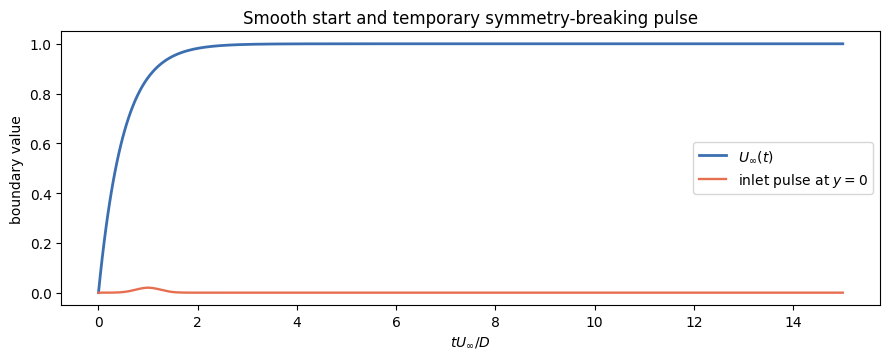

In [3]:
RAMP_RATE = 2.0
PULSE_AMPLITUDE = 0.02
PULSE_TIME = 1.0
PULSE_WIDTH = 0.35

def free_stream(t):
    "Smooth start from rest to U_infinity = 1."
    return 1.0-torch.exp(-RAMP_RATE*t)

def inlet_crossflow(y,t):
    "Small temporary symmetry-breaking pulse; zero at y = +/- YMAX."
    shape = torch.cos(0.5*math.pi*y/YMAX)
    pulse = torch.exp(-((t-PULSE_TIME)/PULSE_WIDTH)**2)
    return PULSE_AMPLITUDE*shape*pulse

def inside_fluid(x,y):
    "Boolean mask for the rectangular box outside the cylinder."
    return (x>=XMIN)&(x<=XMAX)&(y>=YMIN)&(y<=YMAX)&(x*x+y*y>=R*R)

NU = 1.0/RE_TARGET
ST_REFERENCE = 0.16
PERIOD_REFERENCE = 1.0/ST_REFERENCE

t_ref=torch.linspace(0,T_MAX,401,device=device).reshape(-1,1)
y_mid=torch.zeros_like(t_ref)
U_ref=free_stream(t_ref)
V_seed=inlet_crossflow(y_mid,t_ref)

print(f"cylinder diameter D:       {D:.2f}")
print(f"target viscosity 1/Re_D:  {NU:.5f}")
print(f"final free-stream speed:  {U_ref[-1].item():.6f}")
print(f"maximum inlet v pulse:    {V_seed.abs().max().item():.5f}")
print(f"comparison period 1/St:   {PERIOD_REFERENCE:.3f}")

fig,ax=plt.subplots(figsize=(9,3.7))
ax.plot(t_ref.cpu(),U_ref.cpu(),color=BLUE,lw=2,label=r'$U_\infty(t)$')
ax.plot(t_ref.cpu(),V_seed.cpu(),color=CORAL,lw=1.7,label='inlet pulse at $y=0$')
ax.set_xlabel(r'$tU_\infty/D$'); ax.set_ylabel('boundary value')
ax.set_title('Smooth start and temporary symmetry-breaking pulse')
ax.legend(); plt.tight_layout(); plt.show()

---

## 5 — Collocation and boundary points

The exterior domain needs more than uniform random points. We combine:

1. points across the whole box,
2. extra points in the downstream wake,
3. an annulus of points near the cylinder,
4. extra late-time wake points.

Boundary points are sampled on the inlet, outlet, far field, and circular cylinder. Initial-condition points fill the fluid at $t=0$.

The arrays below cover the full time interval. During training, the same times are compressed into the current continuation horizon.

In [4]:
gen = torch.Generator().manual_seed(42)

def rand_between(a,b,n):
    return (a+(b-a)*torch.rand(n,1,generator=gen)).to(device)

def sample_box_outside_cylinder(n,x0,x1,y0,y1,t0=0.0,t1=T_MAX):
    "Rejection sample a rectangular space-time box outside the cylinder."
    parts=[]; count=0
    while count<n:
        m=max(32,2*(n-count))
        x=rand_between(x0,x1,m); y=rand_between(y0,y1,m); t=rand_between(t0,t1,m)
        keep=(x[:,0]**2+y[:,0]**2)>(R+1e-3)**2
        q=torch.cat([x[keep],y[keep],t[keep]],dim=1)
        parts.append(q); count+=q.shape[0]
    return torch.cat(parts,dim=0)[:n]

def sample_annulus(n,t0=0.0,t1=T_MAX,outer=1.5):
    "Area-uniform annulus around the cylinder."
    q=torch.rand(n,1,generator=gen).to(device)
    rr=torch.sqrt(R**2+q*(outer**2-R**2))
    th=rand_between(0.0,2.0*math.pi,n)
    tt=rand_between(t0,t1,n)
    return torch.cat([rr*torch.cos(th),rr*torch.sin(th),tt],dim=1)

def sample_interior(n,tmax=T_MAX):
    "Interior space-time points with deliberate wake and cylinder resolution."
    n_uniform=int(0.35*n)
    n_wake=int(0.35*n)
    n_near=int(0.20*n)
    n_late=n-n_uniform-n_wake-n_near

    uniform=sample_box_outside_cylinder(n_uniform,XMIN,XMAX,YMIN,YMAX,0.0,tmax)
    wake=sample_box_outside_cylinder(n_wake,-0.75,9.0,-2.2,2.2,0.0,tmax)
    near=sample_annulus(n_near,0.0,tmax,outer=1.6)
    late=sample_box_outside_cylinder(n_late,-0.25,10.0,-2.5,2.5,0.45*tmax,tmax)
    return torch.cat([uniform,wake,near,late],dim=0)

# full-horizon base arrays
xyt_f_base=sample_interior(N_f,T_MAX)

xyt_in_base=torch.cat([XMIN*torch.ones(N_b,1,device=device),
                       rand_between(YMIN,YMAX,N_b),rand_between(0,T_MAX,N_b)],dim=1)
xyt_out_base=torch.cat([XMAX*torch.ones(N_b,1,device=device),
                        rand_between(YMIN,YMAX,N_b),rand_between(0,T_MAX,N_b)],dim=1)

top=torch.cat([rand_between(XMIN,XMAX,N_b),YMAX*torch.ones(N_b,1,device=device),
               rand_between(0,T_MAX,N_b)],dim=1)
bottom=torch.cat([rand_between(XMIN,XMAX,N_b),YMIN*torch.ones(N_b,1,device=device),
                  rand_between(0,T_MAX,N_b)],dim=1)
xyt_far_base=torch.cat([top,bottom],dim=0)

theta=rand_between(0,2*math.pi,2*N_b)
xyt_cyl_base=torch.cat([R*torch.cos(theta),R*torch.sin(theta),
                        rand_between(0,T_MAX,2*N_b)],dim=1)

xy0=sample_box_outside_cylinder(N_0,XMIN,XMAX,YMIN,YMAX,0.0,0.0)
xy0[:,2]=0.0
xyt_0=xy0

def scaled_time(q,Tstage,needs_grad=False):
    z=q.detach().clone()
    z[:,2:3]*=Tstage/T_MAX
    return z.requires_grad_(needs_grad)

# start with the first continuation horizon
xyt_f=scaled_time(xyt_f_base,TRAINING_STAGES[0][1],True)
xyt_in=scaled_time(xyt_in_base,TRAINING_STAGES[0][1])
xyt_out=scaled_time(xyt_out_base,TRAINING_STAGES[0][1],True)
xyt_far=scaled_time(xyt_far_base,TRAINING_STAGES[0][1])
xyt_cyl=scaled_time(xyt_cyl_base,TRAINING_STAGES[0][1])

print(f"interior space-time points: {xyt_f.shape[0]}")
print(f"inlet: {xyt_in.shape[0]} | outlet: {xyt_out.shape[0]} | far field: {xyt_far.shape[0]}")
print(f"cylinder: {xyt_cyl.shape[0]} | initial: {xyt_0.shape[0]}")

interior space-time points: 7000
inlet: 500 | outlet: 500 | far field: 1000
cylinder: 1000 | initial: 1000


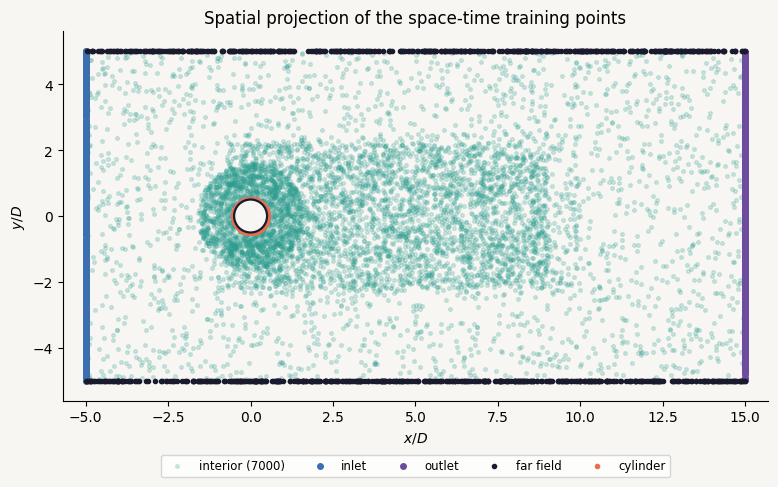

In [5]:
def np2(t):
    return t.detach().cpu().numpy()

CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"; BLUE="#3B6FB0"; BG="#f7f6f2"
fig,ax=plt.subplots(figsize=(12,5.0)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

f=np2(xyt_f_base); bi=np2(xyt_in_base); bo=np2(xyt_out_base)
bf=np2(xyt_far_base); bc=np2(xyt_cyl_base)
ax.scatter(f[:,0],f[:,1],s=7,alpha=0.20,color=TEAL,label=f"interior ({len(f)})")
ax.scatter(bi[:,0],bi[:,1],s=16,color=BLUE,label="inlet")
ax.scatter(bo[:,0],bo[:,1],s=16,color=PUR,label="outlet")
ax.scatter(bf[:,0],bf[:,1],s=9,color=INK,label="far field")
ax.scatter(bc[:,0],bc[:,1],s=9,color=CORAL,label="cylinder")
ax.add_patch(Circle((0,0),R,facecolor=BG,edgecolor=INK,lw=1.6,zorder=6))

ax.set_xlim(XMIN-0.7,XMAX+0.7); ax.set_ylim(YMIN-0.6,YMAX+0.6); ax.set_aspect('equal')
ax.set_xlabel('$x/D$'); ax.set_ylabel('$y/D$')
ax.set_title("Spatial projection of the space-time training points")
ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.13),ncol=5,fontsize=8.5)
for q in ['top','right']: ax.spines[q].set_visible(False)
plt.tight_layout(); plt.show()

---

## 6 — The network

The coding pattern is unchanged. The input now has three coordinates, $(x,y,t)$, and the output still contains $(u,v,p)$. Scaling each input to approximately $[-1,1]$ is especially important because the streamwise coordinate and time horizon are much larger than the cylinder diameter.

In [6]:
class PINN(nn.Module):
    "Input (x,y,t) -> outputs (u,v,p)."
    def __init__(self,n_hidden=80,n_layers=6):
        super().__init__()
        layers=[nn.Linear(3,n_hidden),nn.Tanh()]
        for _ in range(n_layers-1):
            layers += [nn.Linear(n_hidden,n_hidden),nn.Tanh()]
        layers += [nn.Linear(n_hidden,3)]
        self.net=nn.Sequential(*layers)
        self.register_buffer('lb',torch.tensor([XMIN,YMIN,0.0]))
        self.register_buffer('ub',torch.tensor([XMAX,YMAX,T_MAX]))
        for m in self.net:
            if isinstance(m,nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self,xyt):
        z=2.0*(xyt-self.lb)/(self.ub-self.lb)-1.0
        return self.net(z)

model=PINN().to(device)
n_params=sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")

PINN(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=80, bias=True)
    (1): Tanh()
    (2): Linear(in_features=80, out_features=80, bias=True)
    (3): Tanh()
    (4): Linear(in_features=80, out_features=80, bias=True)
    (5): Tanh()
    (6): Linear(in_features=80, out_features=80, bias=True)
    (7): Tanh()
    (8): Linear(in_features=80, out_features=80, bias=True)
    (9): Tanh()
    (10): Linear(in_features=80, out_features=80, bias=True)
    (11): Tanh()
    (12): Linear(in_features=80, out_features=3, bias=True)
  )
)
Trainable parameters: 32963


---

## 7 — The predicted fields and automatic differentiation

The network fields now depend on time:

$$
u=u(x,y,t),\qquad v=v(x,y,t),\qquad p=p(x,y,t).
$$

The same `grad` helper returns all derivatives with respect to $(x,y,t)$. The column order is therefore $x$, $y$, then $t$.

In [7]:
def fields(xyt):
    "Network fields u(x,y,t), v(x,y,t), p(x,y,t)."
    out=model(xyt)
    return out[:,0:1],out[:,1:2],out[:,2:3]

def grad(o,i):
    return torch.autograd.grad(o,i,torch.ones_like(o),create_graph=True,retain_graph=True)[0]

# verify shapes before training
u0,v0,p0=fields(xyt_f[:8])
print(f"u shape: {tuple(u0.shape)} | v shape: {tuple(v0.shape)} | p shape: {tuple(p0.shape)}")
print(f"untrained mean values: u={u0.mean().item():+.3e}, "
      f"v={v0.mean().item():+.3e}, p={p0.mean().item():+.3e}")

u shape: (8, 1) | v shape: (8, 1) | p shape: (8, 1)
untrained mean values: u=-1.918e-01, v=-1.228e-01, p=+6.395e-03


---

## 8 — The residual: unsteady momentum plus continuity

Automatic differentiation now supplies first derivatives in time as well as the spatial gradients and Laplacians:

$$
\begin{aligned}
r_x &= u_t+u u_x+v u_y+p_x-\frac{1}{Re_D}(u_{xx}+u_{yy}),\\
r_y &= v_t+u v_x+v v_y+p_y-\frac{1}{Re_D}(v_{xx}+v_{yy}),\\
r_c &= u_x+v_y.
\end{aligned}
$$

A perfect solution makes all three residuals zero throughout space and time.

In [8]:
def residuals(xyt,Re):
    "Unsteady x-momentum, y-momentum, and continuity residuals."
    u,v,p=fields(xyt)

    gu=grad(u,xyt); gv=grad(v,xyt); gp=grad(p,xyt)
    u_x,u_y,u_t=gu[:,0:1],gu[:,1:2],gu[:,2:3]
    v_x,v_y,v_t=gv[:,0:1],gv[:,1:2],gv[:,2:3]
    p_x,p_y=gp[:,0:1],gp[:,1:2]

    u_xx=grad(u_x,xyt)[:,0:1]; u_yy=grad(u_y,xyt)[:,1:2]
    v_xx=grad(v_x,xyt)[:,0:1]; v_yy=grad(v_y,xyt)[:,1:2]

    r_x=u_t+u*u_x+v*u_y+p_x-(u_xx+u_yy)/Re
    r_y=v_t+u*v_x+v*v_y+p_y-(v_xx+v_yy)/Re
    r_c=u_x+v_y
    return r_x,r_y,r_c

# demo on the untrained network
r_x,r_y,r_c=residuals(xyt_f[:64],RE_TARGET)
print(f"residual shapes: {tuple(r_x.shape)}, {tuple(r_y.shape)}, {tuple(r_c.shape)}")
print(f"untrained RMS: rx={r_x.square().mean().sqrt().item():.3e}, "
      f"ry={r_y.square().mean().sqrt().item():.3e}, rc={r_c.square().mean().sqrt().item():.3e}")

residual shapes: (64, 1), (64, 1), (64, 1)
untrained RMS: rx=3.235e-02, ry=2.215e-02, rc=6.943e-02


---

## 9 — The loss

The total loss keeps every physical family visible:

$$
\mathcal L=\mathcal L_{PDE}
+\lambda_0\mathcal L_{initial}
+\lambda_i\mathcal L_{inlet}
+\lambda_f\mathcal L_{far}
+\lambda_c\mathcal L_{cylinder}
+\lambda_o\mathcal L_{outlet}.
$$

The cylinder is given the largest starting weight because a small slip velocity can strongly contaminate drag, lift, and the near wake. As before, the weights are engineering starting values rather than universal constants.

In [9]:
W_INITIAL=10.0
W_INLET=10.0
W_FAR=5.0
W_CYLINDER=20.0
W_OUTLET=1.0

def mse(z): return (z**2).mean()

def compute_losses(Re):
    # interior unsteady Navier-Stokes equations
    r_x,r_y,r_c=residuals(xyt_f,Re)
    loss_pde=mse(r_x)+mse(r_y)+mse(r_c)

    # initial condition: fluid starts from rest
    u0,v0,_=fields(xyt_0)
    loss_0=mse(u0)+mse(v0)

    # inlet: smooth free stream plus the small temporary pulse
    ui,vi,_=fields(xyt_in)
    ti=xyt_in[:,2:3]; yi=xyt_in[:,1:2]
    loss_in=mse(ui-free_stream(ti))+mse(vi-inlet_crossflow(yi,ti))

    # top and bottom far field
    uf,vf,_=fields(xyt_far)
    tf=xyt_far[:,2:3]
    loss_far=mse(uf-free_stream(tf))+mse(vf)

    # cylinder no slip
    uc,vc,_=fields(xyt_cyl)
    loss_cyl=mse(uc)+mse(vc)

    # outlet: zero velocity gradients and pressure gauge
    uo,vo,po=fields(xyt_out)
    u_x=grad(uo,xyt_out)[:,0:1]
    v_x=grad(vo,xyt_out)[:,0:1]
    loss_out=mse(u_x)+mse(v_x)+mse(po)
    return loss_pde,loss_0,loss_in,loss_far,loss_cyl,loss_out

def total_loss(Re):
    lp,l0,li,lf,lc,lo=compute_losses(Re)
    return lp+W_INITIAL*l0+W_INLET*li+W_FAR*lf+W_CYLINDER*lc+W_OUTLET*lo

# demo on the untrained network
lp,l0,li,lf,lc,lo=compute_losses(TRAINING_STAGES[0][0])
print(f"untrained: pde={lp.item():.3e} initial={l0.item():.3e} inlet={li.item():.3e} "
      f"far={lf.item():.3e} cylinder={lc.item():.3e} outlet={lo.item():.3e}")

untrained: pde=7.649e-03 initial=1.036e-01 inlet=8.253e-01 far=1.157e+00 cylinder=1.316e-02 outlet=7.532e-03


---

## 10 — Two-phase training: Adam → L-BFGS

The optimizer sequence stays the same as Tutorial 6. Adam first finds a useful basin; L-BFGS then polishes the final full-batch residual.

The new continuation pairs a Reynolds number with a time horizon:

| Stage | $Re_D$ | active horizon |
|------:|-------:|---------------:|
| 1 | 20 | $0\le t\le3$ |
| 2 | 60 | $0\le t\le8$ |
| 3 | 100 | $0\le t\le15$ |

This is still a laminar Navier–Stokes model. The continuation only makes the optimization problem easier by introducing inertia and long-time dynamics gradually.

In [10]:
def activate_horizon(Tstage):
    "Compress the full-horizon base samples into 0 <= t <= Tstage."
    global xyt_f,xyt_in,xyt_out,xyt_far,xyt_cyl
    xyt_f=scaled_time(xyt_f_base,Tstage,True)
    xyt_in=scaled_time(xyt_in_base,Tstage)
    xyt_out=scaled_time(xyt_out_base,Tstage,True)
    xyt_far=scaled_time(xyt_far_base,Tstage)
    xyt_cyl=scaled_time(xyt_cyl_base,Tstage)

@torch.no_grad()
def mass_flow(x0,t0,n=241):
    y=torch.linspace(YMIN,YMAX,n,device=device).reshape(-1,1)
    x=x0*torch.ones_like(y); t=t0*torch.ones_like(y)
    u,_,_=fields(torch.cat([x,y,t],dim=1))
    return torch.trapz(u[:,0],y[:,0]).item()

@torch.no_grad()
def wake_probe(t0):
    q=torch.tensor([[3.0,0.75,t0]],dtype=torch.float32,device=device)
    _,v,_=fields(q)
    return v.item()

history={"epoch":[],"total":[],"pde":[],"initial":[],"inlet":[],"far":[],
         "cylinder":[],"outlet":[],"probe_v":[],"mass":[],"phase":[],"Re":[],"T":[]}

def record(epoch,phase,Re,Tstage):
    lp,l0,li,lf,lc,lo=compute_losses(Re)
    total=lp+W_INITIAL*l0+W_INLET*li+W_FAR*lf+W_CYLINDER*lc+W_OUTLET*lo
    q_ref=(YMAX-YMIN)*free_stream(torch.tensor([[Tstage]],device=device)).item()
    history["epoch"].append(epoch); history["total"].append(total.item())
    history["pde"].append(lp.item()); history["initial"].append(l0.item())
    history["inlet"].append(li.item()); history["far"].append(lf.item())
    history["cylinder"].append(lc.item()); history["outlet"].append(lo.item())
    history["probe_v"].append(wake_probe(Tstage))
    history["mass"].append(abs(mass_flow(0.8*XMAX,Tstage)-q_ref))
    history["phase"].append(phase); history["Re"].append(Re); history["T"].append(Tstage)

# --- Stage 1: Adam, with Reynolds and time-horizon continuation ---
opt=torch.optim.Adam(model.parameters(),lr=1e-3)
step=0
start=time.time()
for Re,Tstage in TRAINING_STAGES:
    activate_horizon(Tstage)
    print(f"\nAdam stage: Re_D={Re:g}, 0 <= t <= {Tstage:g}")
    for local in range(ADAM_ITERS_PER_STAGE+1):
        opt.zero_grad(); total_loss(Re).backward(); opt.step()
        if local % LOG_EVERY == 0:
            record(step,"Adam",Re,Tstage)
            print(f"[Adam] step={step:5d} Re={Re:5.1f} T={Tstage:4.1f} "
                  f"loss={history['total'][-1]:.3e} v_probe={history['probe_v'][-1]:+.3e} "
                  f"mass_err={history['mass'][-1]:.2e}")
        step+=1

# --- Stage 2: L-BFGS at the target Reynolds number and full horizon ---
activate_horizon(T_MAX)
HANDOFF=step
if RUN_LBFGS:
    opt=torch.optim.LBFGS(model.parameters(),lr=1.0,max_iter=LBFGS_ITERS,history_size=50,
                          line_search_fn='strong_wolfe',tolerance_grad=1e-10,tolerance_change=1e-12)
    calls=[0]
    def closure():
        opt.zero_grad(); L=total_loss(RE_TARGET); L.backward(); calls[0]+=1
        if calls[0] % max(1,LBFGS_ITERS//10) == 0:
            record(HANDOFF+calls[0],"LBFGS",RE_TARGET,T_MAX)
        return L
    opt.step(closure)

record(HANDOFF+LBFGS_ITERS+1,"LBFGS",RE_TARGET,T_MAX)
elapsed=(time.time()-start)/60
q_final=(YMAX-YMIN)*free_stream(torch.tensor([[T_MAX]],device=device)).item()
print(f"\nTraining complete in {elapsed:.2f} min")
print(f"final wake probe v:       {wake_probe(T_MAX):+.5f}")
print(f"final mass-flow error:    {abs(mass_flow(0.8*XMAX,T_MAX)-q_final):.3e}")

torch.save({"model_state":model.state_dict(),"history":history,
            "Re":RE_TARGET,"T_MAX":T_MAX},
           "cylinder_vortex_pinn_tutorial_style.pt")
print("saved: cylinder_vortex_pinn_tutorial_style.pt")


Adam stage: Re_D=20, 0 <= t <= 3
[Adam] step=    0 Re= 20.0 T= 3.0 loss=8.464e+00 v_probe=+4.685e-02 mass_err=1.05e+01
[Adam] step=  100 Re= 20.0 T= 3.0 loss=1.110e+00 v_probe=+1.043e-02 mass_err=6.26e+00
[Adam] step=  200 Re= 20.0 T= 3.0 loss=5.781e-01 v_probe=+5.381e-03 mass_err=3.23e+00
[Adam] step=  300 Re= 20.0 T= 3.0 loss=3.779e-01 v_probe=-4.000e-03 mass_err=3.34e+00
[Adam] step=  400 Re= 20.0 T= 3.0 loss=2.691e-01 v_probe=+1.285e-03 mass_err=3.95e+00
[Adam] step=  500 Re= 20.0 T= 3.0 loss=2.132e-01 v_probe=+2.458e-03 mass_err=4.40e+00
[Adam] step=  600 Re= 20.0 T= 3.0 loss=1.683e-01 v_probe=+1.560e-03 mass_err=4.65e+00
[Adam] step=  700 Re= 20.0 T= 3.0 loss=1.289e-01 v_probe=-1.802e-03 mass_err=4.70e+00
[Adam] step=  800 Re= 20.0 T= 3.0 loss=1.013e-01 v_probe=-6.539e-03 mass_err=4.79e+00
[Adam] step=  900 Re= 20.0 T= 3.0 loss=8.211e-02 v_probe=-8.173e-03 mass_err=4.89e+00
[Adam] step= 1000 Re= 20.0 T= 3.0 loss=7.207e-02 v_probe=-1.412e-02 mass_err=5.00e+00
[Adam] step= 1100 Re

---

## 11 — The Loss History, Both Phases

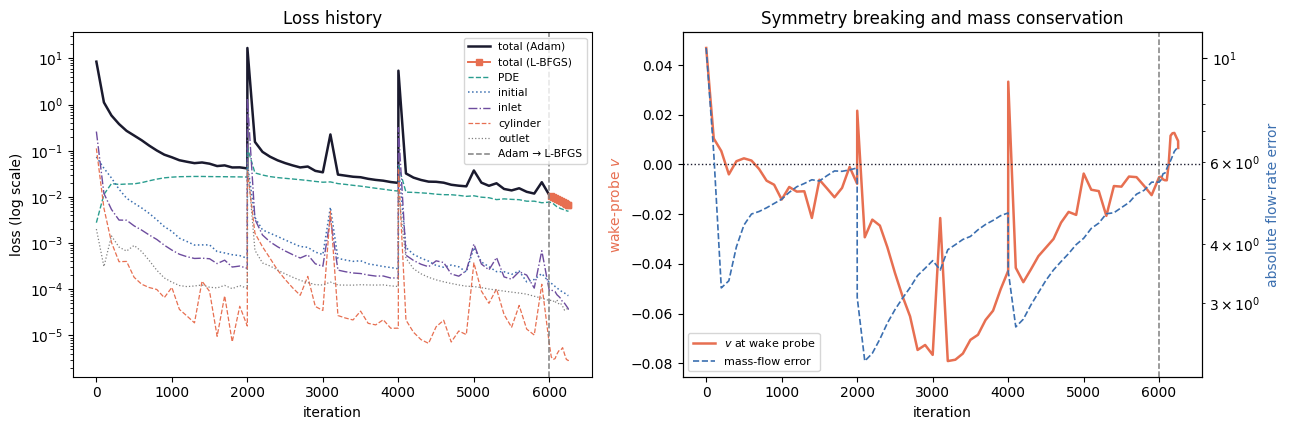

In [11]:
epoch=np.array(history["epoch"])
tot=np.array(history["total"]); pde=np.array(history["pde"])
initial=np.array(history["initial"]); inlet=np.array(history["inlet"])
far=np.array(history["far"]); cylinder=np.array(history["cylinder"]); outlet=np.array(history["outlet"])
probe=np.array(history["probe_v"]); mass=np.array(history["mass"])
ph=np.array(history["phase"]); am=ph=="Adam"; lm=ph=="LBFGS"
INK="#1A1A2E"; CORAL="#E76F51"; TEAL="#2A9D8F"; PUR="#6D4C9E"; BLUE="#3B6FB0"

fig,ax=plt.subplots(1,2,figsize=(13,4.4))

# loss components
ax[0].semilogy(epoch[am],tot[am],'-',color=INK,lw=1.8,label='total (Adam)')
ax[0].semilogy(epoch[lm],tot[lm],'s-',color=CORAL,ms=4,lw=1.4,label='total (L-BFGS)')
ax[0].semilogy(epoch,pde,'--',color=TEAL,lw=1.0,label='PDE')
ax[0].semilogy(epoch,np.maximum(initial,1e-14),':',color=BLUE,lw=1.1,label='initial')
ax[0].semilogy(epoch,np.maximum(inlet,1e-14),'-.',color=PUR,lw=1.0,label='inlet')
ax[0].semilogy(epoch,np.maximum(cylinder,1e-14),'--',color=CORAL,lw=0.9,label='cylinder')
ax[0].semilogy(epoch,np.maximum(outlet,1e-14),':',color='gray',lw=0.9,label='outlet')
ax[0].axvline(HANDOFF,color='gray',ls='--',lw=1.1,label='Adam → L-BFGS')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss (log scale)')
ax[0].set_title('Loss history'); ax[0].legend(fontsize=7.7)

# physical indicators
ax2=ax[1]; ax3=ax2.twinx()
ax2.plot(epoch,probe,'-',color=CORAL,lw=1.8,label='$v$ at wake probe')
ax2.axhline(0,color=INK,ls=':',lw=1)
ax3.semilogy(epoch,np.maximum(mass,1e-12),'--',color=BLUE,lw=1.2,label='mass-flow error')
ax2.axvline(HANDOFF,color='gray',ls='--',lw=1.1)
ax2.set_xlabel('iteration'); ax2.set_ylabel('wake-probe $v$',color=CORAL)
ax3.set_ylabel('absolute flow-rate error',color=BLUE)
ax2.set_title('Symmetry breaking and mass conservation')
h1,l1=ax2.get_legend_handles_labels(); h2,l2=ax3.get_legend_handles_labels()
ax2.legend(h1+h2,l1+l2,fontsize=8,loc='best')
plt.tight_layout(); plt.show()

---

## 12 — Results and validation

The final-time fields answer the qualitative questions first: is the cylinder no-slip, is there a downstream wake, and has the solution developed top–bottom asymmetry?

The second group of diagnostics is stricter. We inspect vorticity snapshots, independent residuals, boundary errors, mass conservation, force coefficients, and the dominant frequency of the lift signal. A low total loss alone is not accepted as validation.

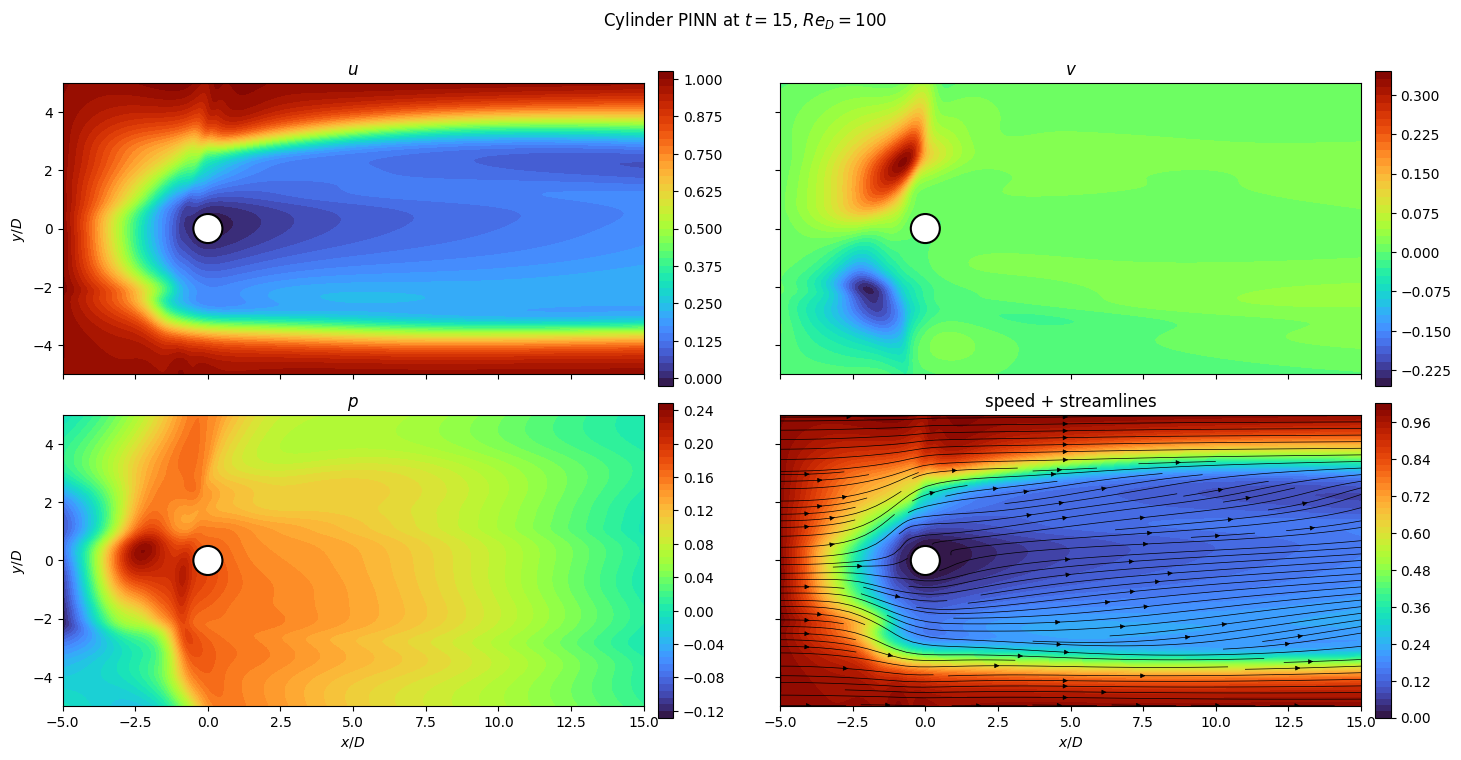

In [12]:
# regular final-time prediction grid
nx,ny=(361,181) if FULL_TRAINING else (141,71)
xg=np.linspace(XMIN,XMAX,nx); yg=np.linspace(YMIN,YMAX,ny)
X,Y=np.meshgrid(xg,yg)
mask=inside_fluid(X,Y)
pts=np.column_stack([X[mask],Y[mask],T_MAX*np.ones(mask.sum())])

with torch.no_grad():
    pred=model(torch.tensor(pts,dtype=torch.float32,device=device)).cpu().numpy()

U=np.full_like(X,np.nan,dtype=float); V=np.full_like(X,np.nan,dtype=float)
P=np.full_like(X,np.nan,dtype=float)
U[mask]=pred[:,0]; V[mask]=pred[:,1]; P[mask]=pred[:,2]
SPEED=np.sqrt(U**2+V**2)

fig,ax=plt.subplots(2,2,figsize=(15,7.4),sharex=True,sharey=True)
fields_plot=[(U,'$u$'),(V,'$v$'),(P,'$p$'),(SPEED,'speed + streamlines')]
for a,(F,title) in zip(ax.flat,fields_plot):
    c=a.contourf(X,Y,F,levels=50,cmap='turbo')
    plt.colorbar(c,ax=a,pad=0.02)
    a.add_patch(Circle((0,0),R,facecolor='white',edgecolor='k',lw=1.5,zorder=6))
    a.set_title(title); a.set_aspect('equal')
    a.set_xlim(XMIN,XMAX); a.set_ylim(YMIN,YMAX)

# streamlines on the speed panel
ax[1,1].streamplot(xg,yg,np.ma.masked_invalid(U),np.ma.masked_invalid(V),
                   density=1.5,color='k',linewidth=0.5,arrowsize=0.7)
for a in ax[:,0]: a.set_ylabel('$y/D$')
for a in ax[1,:]: a.set_xlabel('$x/D$')
plt.suptitle(fr'Cylinder PINN at $t={T_MAX:g}$, $Re_D={RE_TARGET:g}$',y=1.01)
plt.tight_layout(); plt.show()

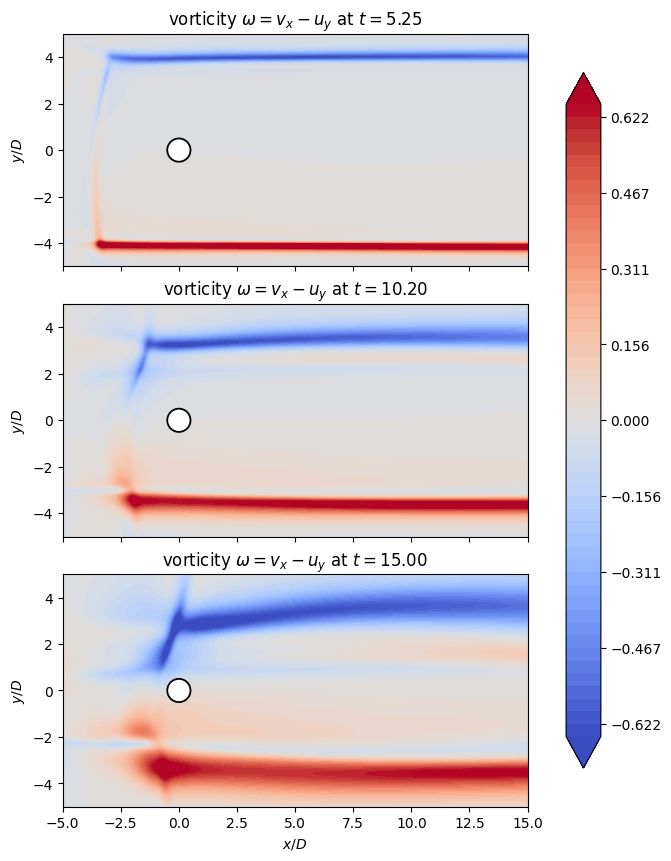

independent residual RMS: rx=4.336e-02, ry=1.443e-02, continuity=6.488e-02
inlet velocity RMS error: 6.008e-03
maximum cylinder speed:   8.527e-03
outlet pressure RMS:      4.330e-03
mass flow at x=  2.0: Q=4.01522  error=-5.98e+00
mass flow at x=  6.0: Q=3.71538  error=-6.28e+00
mass flow at x= 10.0: Q=3.56750  error=-6.43e+00
mass flow at x= 12.0: Q=3.58093  error=-6.42e+00
mean late-time C_D:       +0.0143
late-time C_L RMS:        0.0090
dominant Strouhal number: 0.1311


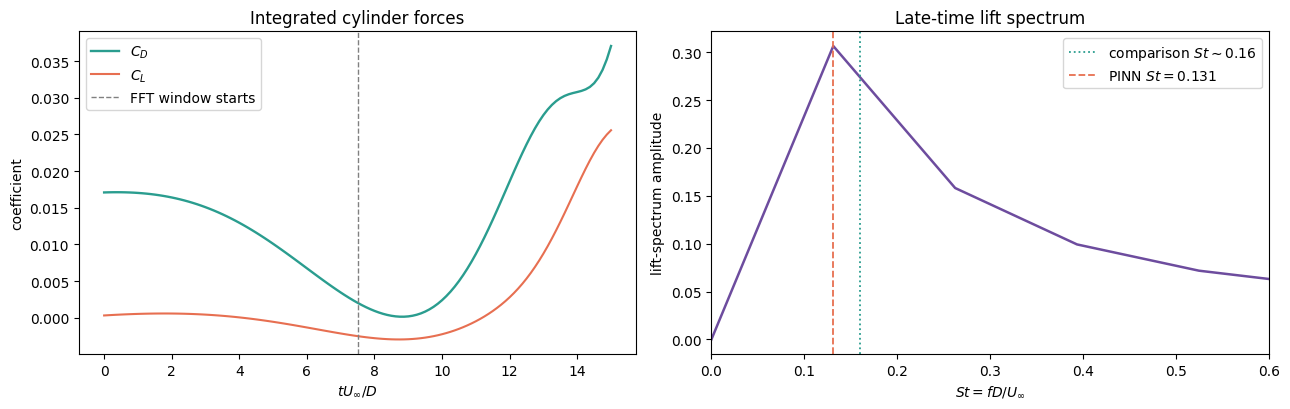

In [13]:
def vorticity_snapshot(t0,nx=241,ny=121,chunk=12000):
    "Return u, v, p, and omega = v_x-u_y on a masked regular grid."
    x=np.linspace(XMIN,XMAX,nx); y=np.linspace(YMIN,YMAX,ny)
    X,Y=np.meshgrid(x,y); mask=inside_fluid(X,Y)
    raw=np.column_stack([X[mask],Y[mask],t0*np.ones(mask.sum())])

    pred_parts=[]; om_parts=[]
    for j in range(0,len(raw),chunk):
        q=torch.tensor(raw[j:j+chunk],dtype=torch.float32,device=device,requires_grad=True)
        u,v,p=fields(q)
        gu=grad(u,q); gv=grad(v,q)
        omega=gv[:,0:1]-gu[:,1:2]
        pred_parts.append(torch.cat([u,v,p],dim=1).detach().cpu().numpy())
        om_parts.append(omega.detach().cpu().numpy())

    pred=np.vstack(pred_parts); om=np.vstack(om_parts)[:,0]
    U=np.full_like(X,np.nan,dtype=float); V=np.full_like(X,np.nan,dtype=float)
    P=np.full_like(X,np.nan,dtype=float); O=np.full_like(X,np.nan,dtype=float)
    U[mask]=pred[:,0]; V[mask]=pred[:,1]; P[mask]=pred[:,2]; O[mask]=om
    return x,y,X,Y,U,V,P,O

def force_coefficients(times,n_theta=181):
    "Pressure + viscous traction integrated around the cylinder."
    cds=[]; cls=[]
    theta=torch.linspace(0,2*math.pi,n_theta,device=device).reshape(-1,1)
    nx=torch.cos(theta); ny=torch.sin(theta)
    for t0 in times:
        q=torch.cat([R*nx,R*ny,t0*torch.ones_like(theta)],dim=1).requires_grad_(True)
        u,v,p=fields(q)
        gu=grad(u,q); gv=grad(v,q)
        ux,uy=gu[:,0:1],gu[:,1:2]
        vx,vy=gv[:,0:1],gv[:,1:2]

        tx=-p*nx+(2*ux*nx+(uy+vx)*ny)/RE_TARGET
        ty=-p*ny+((uy+vx)*nx+2*vy*ny)/RE_TARGET
        fx=R*torch.trapz(tx[:,0],theta[:,0])
        fy=R*torch.trapz(ty[:,0],theta[:,0])
        cds.append((2*fx).detach().item())
        cls.append((2*fy).detach().item())
    return np.asarray(cds),np.asarray(cls)

def dominant_strouhal(times,cl):
    "FFT estimate from the second half of the lift history."
    k=len(times)//2
    tt=np.asarray(times[k:]); sig=np.asarray(cl[k:])-np.mean(cl[k:])
    if len(tt)<8 or np.std(sig)<1e-6:
        return np.nan,np.array([]),np.array([])
    dt=np.mean(np.diff(tt))
    freq=np.fft.rfftfreq(len(sig),d=dt)
    amp=np.abs(np.fft.rfft(sig))
    if len(amp)>0: amp[0]=0.0
    j=np.argmax(amp)
    return freq[j],freq,amp

def independent_residual_rms(n=1000):
    q=sample_interior(n,T_MAX).requires_grad_(True)
    rx,ry,rc=residuals(q,RE_TARGET)
    return [z.square().mean().sqrt().item() for z in (rx,ry,rc)]

# vorticity snapshots
snap_times=[0.35*T_MAX,0.68*T_MAX,T_MAX]
fig,ax=plt.subplots(3,1,figsize=(13,8.5),sharex=True,sharey=True,constrained_layout=True)
for a,t0 in zip(ax,snap_times):
    x,y,Xs,Ys,Us,Vs,Ps,Om=vorticity_snapshot(t0,
        nx=281 if FULL_TRAINING else 121,ny=141 if FULL_TRAINING else 61)
    vmax=np.nanpercentile(np.abs(Om),98)
    c=a.contourf(Xs,Ys,Om,levels=np.linspace(-max(vmax,1e-3),max(vmax,1e-3),51),
                 cmap='coolwarm',extend='both')
    a.add_patch(Circle((0,0),R,facecolor='white',edgecolor='k',lw=1.3,zorder=6))
    a.set_ylabel('$y/D$'); a.set_aspect('equal')
    a.set_title(fr'vorticity $\omega=v_x-u_y$ at $t={t0:.2f}$')
fig.colorbar(c,ax=ax,pad=0.02,shrink=0.9)
ax[-1].set_xlabel('$x/D$')
plt.show()

# force history and frequency
times=np.linspace(0.0,T_MAX,121 if FULL_TRAINING else 25)
cd,cl=force_coefficients(times,n_theta=241 if FULL_TRAINING else 81)
St,freq,amp=dominant_strouhal(times,cl)

rx_rms,ry_rms,rc_rms=independent_residual_rms(2500 if FULL_TRAINING else 120)

# independent boundary checks at the active full horizon arrays
with torch.no_grad():
    ui,vi,_=fields(xyt_in)
    ti=xyt_in[:,2:3]; yi=xyt_in[:,1:2]
    inlet_err=torch.sqrt(((ui-free_stream(ti))**2+(vi-inlet_crossflow(yi,ti))**2).mean()).item()
    uc,vc,_=fields(xyt_cyl)
    cyl_speed=torch.sqrt(uc**2+vc**2).max().item()
    _,_,po=fields(xyt_out)
    outlet_p=torch.sqrt((po**2).mean()).item()

q_ref=(YMAX-YMIN)*free_stream(torch.tensor([[T_MAX]],device=device)).item()
stations=[2.0,6.0,10.0,0.8*XMAX]
flows=[mass_flow(x0,T_MAX) for x0 in stations]

print(f"independent residual RMS: rx={rx_rms:.3e}, ry={ry_rms:.3e}, continuity={rc_rms:.3e}")
print(f"inlet velocity RMS error: {inlet_err:.3e}")
print(f"maximum cylinder speed:   {cyl_speed:.3e}")
print(f"outlet pressure RMS:      {outlet_p:.3e}")
for x0,q in zip(stations,flows):
    print(f"mass flow at x={x0:5.1f}: Q={q:.5f}  error={q-q_ref:+.2e}")
print(f"mean late-time C_D:       {cd[len(cd)//2:].mean():+.4f}")
print(f"late-time C_L RMS:        {np.sqrt(np.mean((cl[len(cl)//2:]-cl[len(cl)//2:].mean())**2)):.4f}")
print(f"dominant Strouhal number: {St:.4f}" if np.isfinite(St) else
      "dominant Strouhal number: not resolved by the current run")

fig,ax=plt.subplots(1,2,figsize=(13,4.2))
ax[0].plot(times,cd,color=TEAL,lw=1.7,label='$C_D$')
ax[0].plot(times,cl,color=CORAL,lw=1.5,label='$C_L$')
ax[0].axvline(0.5*T_MAX,color='gray',ls='--',lw=1,label='FFT window starts')
ax[0].set_xlabel(r'$tU_\infty/D$'); ax[0].set_ylabel('coefficient')
ax[0].set_title('Integrated cylinder forces'); ax[0].legend()
if len(freq):
    ax[1].plot(freq,amp,color=PUR,lw=1.8)
    ax[1].axvline(ST_REFERENCE,color=TEAL,ls=':',lw=1.3,label=fr'comparison $St\sim{ST_REFERENCE}$')
    ax[1].axvline(St,color=CORAL,ls='--',lw=1.3,label=fr'PINN $St={St:.3f}$')
    ax[1].set_xlim(0,0.6); ax[1].legend()
ax[1].set_xlabel(r'$St=fD/U_\infty$'); ax[1].set_ylabel('lift-spectrum amplitude')
ax[1].set_title('Late-time lift spectrum')
plt.tight_layout(); plt.show()

---

## 13 — Exercises

1. **Remove the inlet pulse.** Set `PULSE_AMPLITUDE=0`. Does the PINN remain on a symmetric wake? Compare $C_L(t)$ and vorticity.
2. **Reynolds-number sweep.** Train at $Re_D=40,60,80,100,120$. Identify where a persistent oscillatory lift signal first appears.
3. **Longer time horizon.** Increase `T_MAX` to 25 or 30 and add one more continuation stage. Does the Strouhal estimate become more stable?
4. **Cylinder-focused sampling.** Halve and double the annulus fraction. Compare cylinder slip, mean drag, and near-wall vorticity.
5. **Domain-size study.** Move the top and bottom boundaries from $\pm5D$ to $\pm8D$, and extend the outlet. Quantify the change in force coefficients.
6. **Loss weights.** Sweep `W_CYLINDER`, `W_INITIAL`, and `W_OUTLET`. Judge the solution using component losses and physical diagnostics together.
7. **Hard initial condition.** Modify the network output so $u$ and $v$ are multiplied by a function that vanishes at $t=0$. Compare training against the soft initial loss.
8. **Reference CFD comparison.** Import force histories or vorticity snapshots from a laminar finite-volume simulation and compare fields, $C_D$, $C_L$, and $St$.

## 14 — Failure modes to watch for

| Symptom | Cause | Fix |
|---------|-------|-----|
| **Wake remains perfectly symmetric** | symmetric geometry and data let the optimizer find a symmetric solution | retain the small transient pulse; extend time; increase wake resolution |
| **Oscillations appear only at the inlet frequency** | the imposed pulse is too large or too long | reduce `PULSE_AMPLITUDE` or `PULSE_WIDTH`; verify that the pulse has decayed before measuring $St$ |
| **Cylinder has visible slip** | cylinder loss is too weak or surface sampling is sparse | increase `W_CYLINDER`; add more angular points; enrich the near-cylinder annulus |
| **Lift is noisy although fields look smooth** | force integration uses field derivatives and is more sensitive than velocity plots | train longer; increase cylinder sampling; inspect pressure and shear contributions separately |
| **Mass flow drifts downstream** | continuity or far-field conditions are under-resolved | inspect continuity RMS; increase interior and far-field points |
| **Outlet affects shedding frequency** | the outlet is too close or its derivative condition is too strong | lengthen the domain; reduce `W_OUTLET`; compare force histories |
| **FFT returns a misleading peak** | too little late-time data or only one partial cycle | increase `T_MAX`; discard a longer transient; inspect $C_L(t)$ before trusting the spectrum |
| **L-BFGS runs out of memory** | full-batch second derivatives in $(x,y,t)$ are expensive | reduce `N_f`, network width, `history_size`, or disable L-BFGS |
| **Quick CPU run shows no physics** | the CPU profile is only a code-path check | use CUDA full training before interpreting the wake or force coefficients |

## 15 — Vocabulary

- **Vortex shedding** — periodic release of alternating vortices from opposite sides of a bluff body.
- **Kármán vortex street** — the staggered downstream pattern of alternating vortices.
- **Bluff body** — a body whose flow is dominated by separation rather than streamlined attachment.
- **Strouhal number ($St$)** — non-dimensional shedding frequency, $St=fD/U_\infty$.
- **Drag coefficient ($C_D$)** — streamwise force normalized by $\tfrac12\rho U_\infty^2D$.
- **Lift coefficient ($C_L$)** — cross-stream force normalized by $\tfrac12\rho U_\infty^2D$.
- **Vorticity ($\omega$)** — local fluid rotation; in 2D, $\omega=v_x-u_y$.
- **Wake probe** — a fixed downstream point used to monitor time-dependent velocity.
- **Symmetry breaking** — growth of an asymmetric disturbance from an otherwise symmetric configuration.
- **Time-horizon continuation** — training first on a short interval and progressively extending the final time.
- **Traction** — pressure and viscous stress acting on a surface.
- **Laminar unsteady flow** — time-dependent motion governed by molecular viscosity without turbulence closure.

## 16 — What You Have Built (and Where the Series Goes)

The notebook preserves the Tutorial 6 workflow while adding the minimum machinery required for unsteady bluff-body flow:

| Choice | What it bought |
|--------|---------------|
| diameter, free-stream, and convective-time scaling | all variables remain close to order one |
| exterior-domain and annulus sampling | the PINN resolves both the open flow and curved cylinder boundary |
| direct $(u,v,p)$ network with time input | the formulation stays close to the standard unsteady equations |
| initial, inlet, far-field, cylinder, and outlet losses | every physical constraint remains visible and debuggable |
| short symmetry-breaking pulse | the network is not forced to remain on a perfectly symmetric wake |
| Reynolds and time-horizon continuation | inertia and long-time dynamics are introduced gradually |
| vorticity and force post-processing | wake dynamics are tested with quantities stricter than field plots |
| lift-spectrum estimate | the periodic wake is summarized by a Strouhal number |

The important result is not a low loss or a colorful vortex plot by itself. A credible run must also show low independent residuals, small cylinder slip, acceptable mass conservation, a decayed inlet pulse, a sustained late-time lift oscillation, and a frequency that remains stable when the time window and sampling density are changed.

**The honest engineering verdict:** unsteady cylinder flow is substantially harder for a global PINN than the steady backward-facing step. A conventional transient CFD solver remains the reliable benchmark. The value of this tutorial is that it exposes time derivatives, curved boundaries, instability seeding, force integration, and frequency extraction in one consistent PINN workflow.

*Next up: an inverse PINN, where sparse velocity or force observations are used to identify an unknown viscosity or Reynolds number.*